# Modelo de 10 classes

## Bibliotecas utilizadas

In [2]:
import numpy as np
import os
import re
from matplotlib import pyplot as plt
import tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, InputLayer, Masking
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.utils import to_categorical

## Definição das classes

In [3]:
actions = ['Alergia', 'Autismo', 'Bronquite', 'Caimbra', 'Convulsao', 'Diarreia', 'Fratura', 'Frieira', 'Infarto', 'Sarampo']
label_map = {label:num for num, label in enumerate(actions)}
num_frames = 30

In [4]:
label_map

{'Alergia': 0,
 'Autismo': 1,
 'Bronquite': 2,
 'Caimbra': 3,
 'Convulsao': 4,
 'Diarreia': 5,
 'Fratura': 6,
 'Frieira': 7,
 'Infarto': 8,
 'Sarampo': 9}

## Carregamento dos dados

In [5]:
#Cada sujeito é um fold da validação cruzada (leave-one-subject-out)
subject_names = ['AL','e0','e1','e2','e3','ME','MV','RO','SA','MI']

#Dados de cada sujeito
#X_all: todas as versões de cada vídeo, com augmentation (usadas no treino)
#X_first: só a primeira versão de cada vídeo, sem augmentation (usada na validação)
subject_data = {
    s: {
        'X_all': [], 'y_all': [],
        'X_first': [], 'y_first': []
    }
    for s in subject_names
}

pad = len(str(num_frames - 1)) #Largura do zero à esquerda no nome dos arquivos (00.npy, 01.npy, ...)

#Dados de treino: keypoints com augmentation
for action in actions:
    action_dir = os.path.join('../keypoints_data_augmented', action)
    for video_folder in os.listdir(action_dir):
        #Identifica o sujeito pelo nome da pasta (ex.: Alergia_AL_ALE_AL_01_1 -> AL)
        m = re.search(r'_(%s)_' % '|'.join(subject_names), video_folder)
        if not m:
            raise ValueError(f"Não achou sujeito em {video_folder}")
        subj = m.group(1)

        video_dir = os.path.join(action_dir, video_folder)
        window = []
        for frame_num in range(num_frames):
            fname = f"{frame_num:0{pad}d}.npy"
            fpath = os.path.join(video_dir, fname)
            if not os.path.exists(fpath):
                break
            res = np.load(fpath)
            window.append(res)

        if len(window) == num_frames:
            label = label_map[action]
            subject_data[subj]['X_all'].append(window)
            subject_data[subj]['y_all'].append(label)

#Dados de validação: keypoints sem augmentation, só a primeira versão (_1) de cada vídeo
for action in actions:
    action_dir = os.path.join('../keypoints_data', action)
    for video_folder in os.listdir(action_dir):
        m = re.search(r'_(%s)_' % '|'.join(subject_names), video_folder)
        if not m:
            raise ValueError(f"Não achou sujeito em {video_folder}")
        subj = m.group(1)

        video_dir = os.path.join(action_dir, video_folder)
        window = []
        for frame_num in range(num_frames):
            fname = f"{frame_num:0{pad}d}.npy"
            fpath = os.path.join(video_dir, fname)
            if not os.path.exists(fpath):
                break
            res = np.load(fpath)
            window.append(res)

        if len(window) == num_frames and video_folder.endswith('_1'):
            label = label_map[action]
            subject_data[subj]['X_first'].append(window)
            subject_data[subj]['y_first'].append(label)

#Converte para array e transforma os rótulos em one-hot
for s in subject_names:
    subject_data[s]['X_all'] = np.array(subject_data[s]['X_all'])
    subject_data[s]['y_all'] = to_categorical(subject_data[s]['y_all'], num_classes=len(actions))
    subject_data[s]['X_first'] = np.array(subject_data[s]['X_first'])
    subject_data[s]['y_first'] = to_categorical(subject_data[s]['y_first'], num_classes=len(actions))

## Parâmetros do modelo

In [6]:
neuronios = 64
dropout_recorrente = 0.2 #Taxa do dropout recorrente
batch_size = 128
taxa_aprendizado = 1e-3
weight_decay = 0.005 #Decaimento de peso do AdamW, fixo em todos os experimentos
epocas = 300


pasta_modelos = "models/10_classes"
os.makedirs(pasta_modelos, exist_ok=True)

## Validação cruzada (10-fold, leave-one-subject-out)

2026-10-10 11:46:59.285353: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 238680000 exceeds 10% of free system memory.


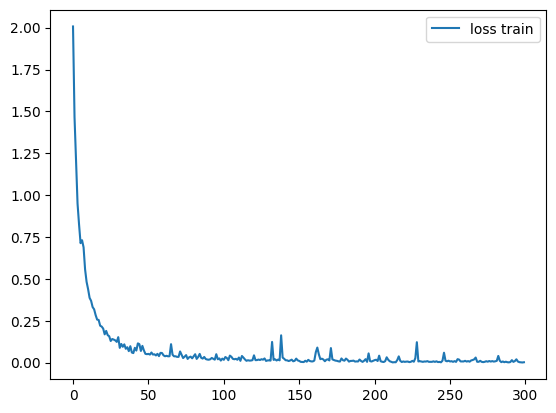

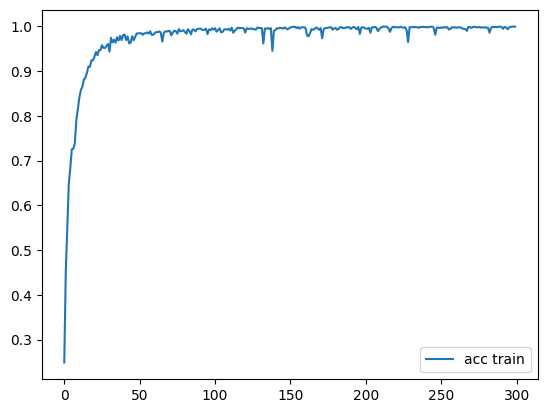

2026-10-10 11:57:22.840095: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 238680000 exceeds 10% of free system memory.


277/277 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step

Fold 1 – Treino (AL excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 0.9977
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Fold 1 – Validação (AL): acc = 0.8400
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 0.8000
  Caimbra: 0.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 0.6000
  Infarto: 1.0000
  Sarampo: 1.0000


2026-10-10 11:57:27.527746: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 240840000 exceeds 10% of free system memory.


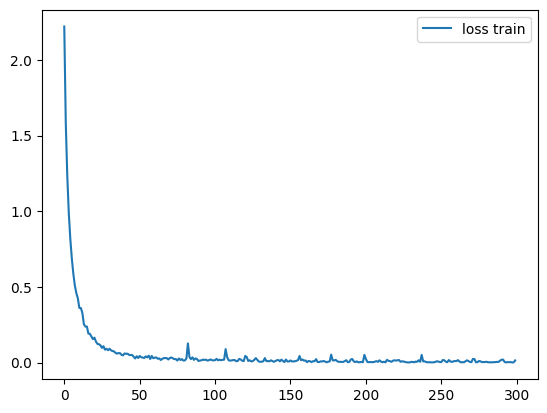

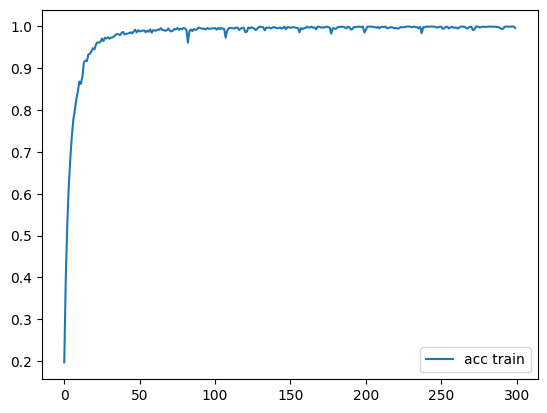

2026-10-10 12:08:01.757583: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 240840000 exceeds 10% of free system memory.


279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 2 – Treino (e0 excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 0.9933
  Diarreia: 1.0000
  Fratura: 0.9544
  Frieira: 0.9600
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Fold 2 – Validação (e0): acc = 0.7391
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 0.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 0.2000
  Infarto: 0.4000
  Sarampo: 1.0000


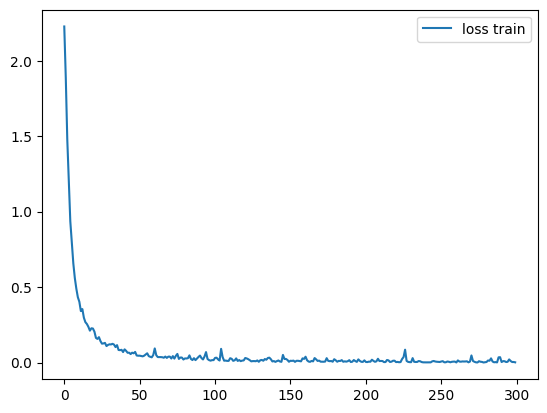

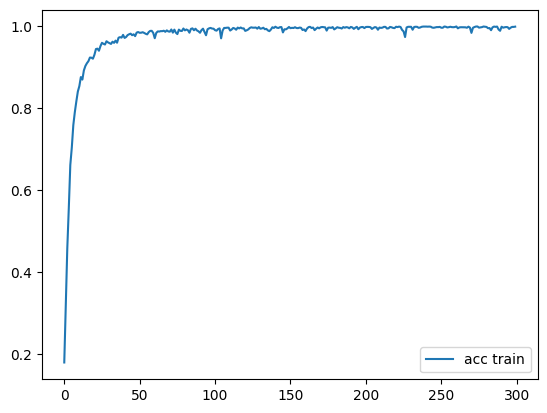

277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 3 – Treino (e1 excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 0.9656
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Fold 3 – Validação (e1): acc = 0.7800
  Alergia: 0.6000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 0.0000
  Convulsao: 0.2000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000


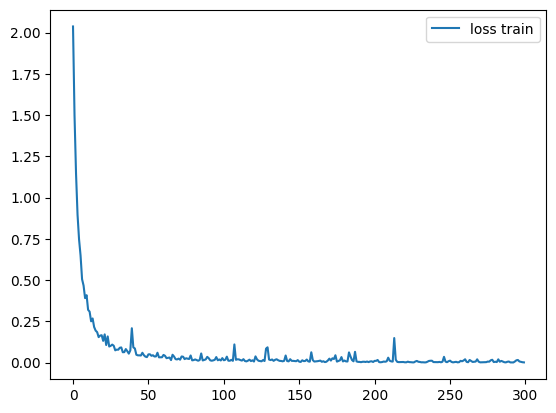

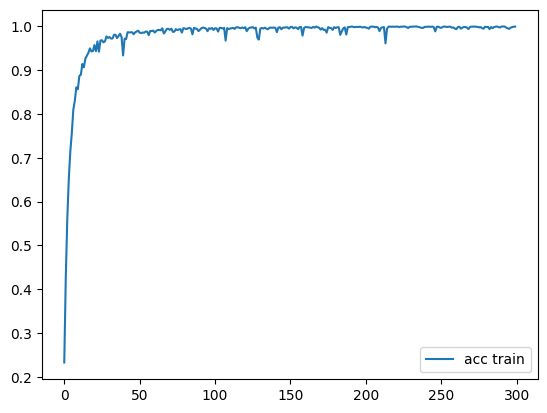

277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 4 – Treino (e2 excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Fold 4 – Validação (e2): acc = 0.9000
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 0.8000
  Frieira: 0.2000
  Infarto: 1.0000
  Sarampo: 1.0000


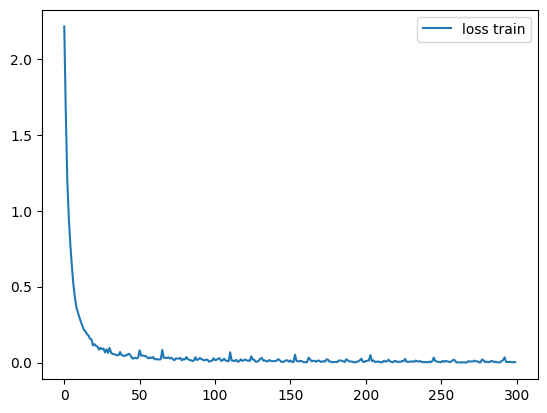

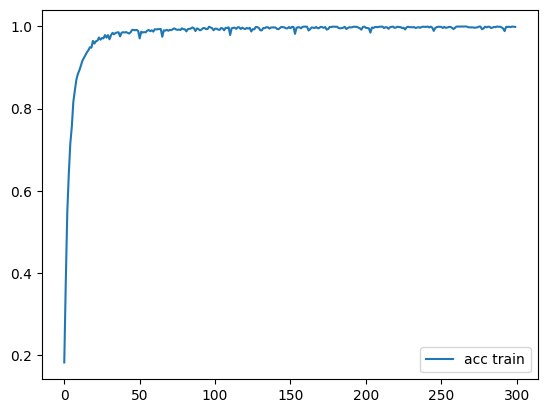

279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step

Fold 5 – Treino (e3 excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 0.9967
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Fold 5 – Validação (e3): acc = 0.8261
  Alergia: 0.4000
  Autismo: 0.8000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 0.6000
  Infarto: 1.0000
  Sarampo: 0.0000


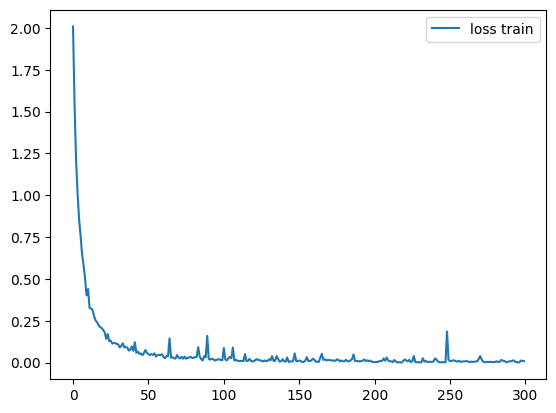

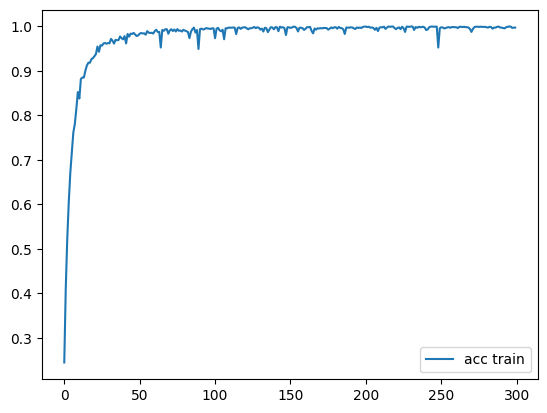

277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step

Fold 6 – Treino (ME excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 0.9849
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Fold 6 – Validação (ME): acc = 0.9000
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 0.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000


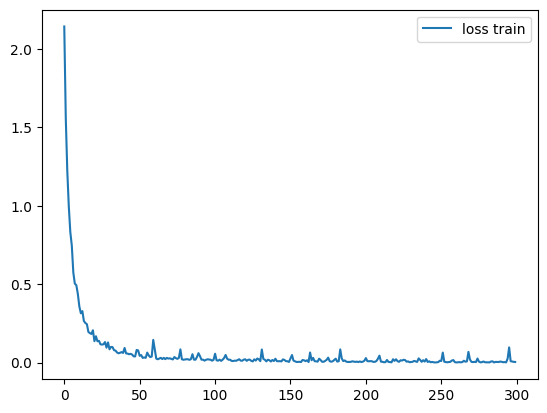

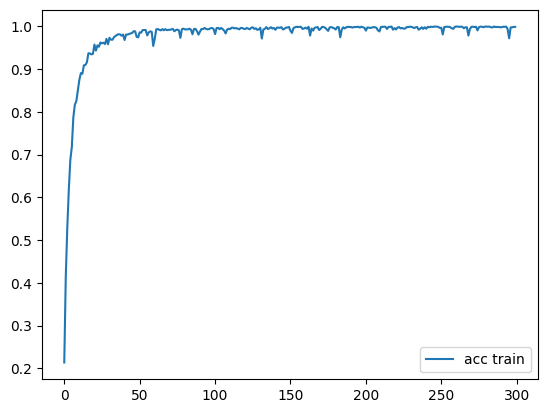

277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 7 – Treino (MV excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 0.9544
  Frieira: 0.9989
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Fold 7 – Validação (MV): acc = 0.8400
  Alergia: 0.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 0.6000
  Frieira: 0.8000
  Infarto: 1.0000
  Sarampo: 1.0000


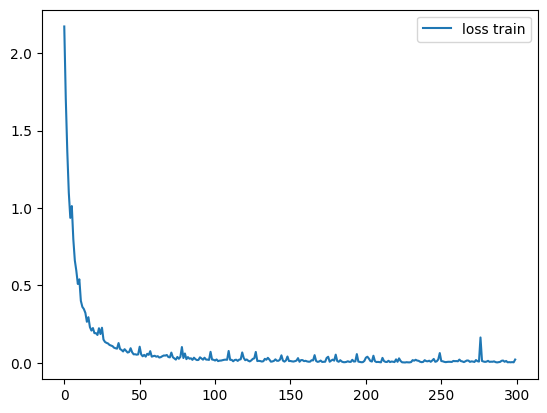

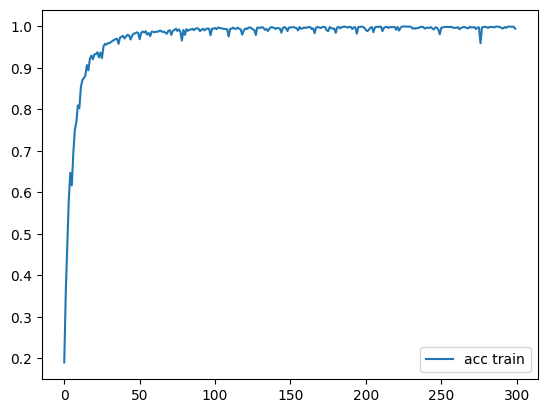

277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 8 – Treino (RO excluído):
  Alergia: 0.9889
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 0.9989
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 0.9988
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Fold 8 – Validação (RO): acc = 0.8800
  Alergia: 0.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 0.8000
  Infarto: 1.0000
  Sarampo: 1.0000


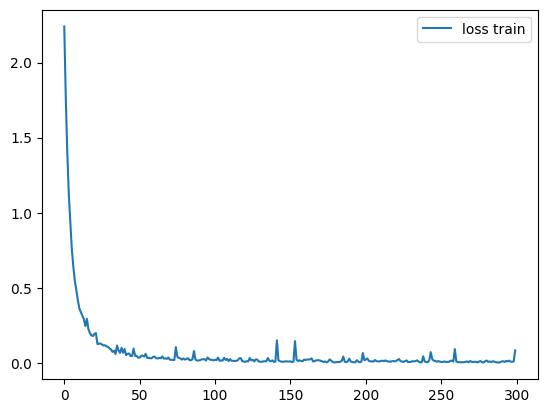

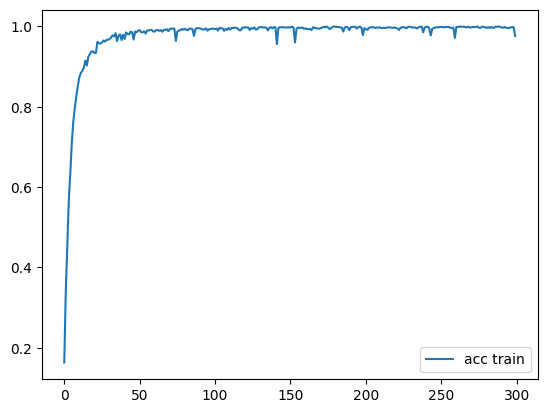

277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 9 – Treino (SA excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 0.9989
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Fold 9 – Validação (SA): acc = 0.8000
  Alergia: 0.4000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 0.8000
  Fratura: 1.0000
  Frieira: 0.6000
  Infarto: 0.2000
  Sarampo: 1.0000


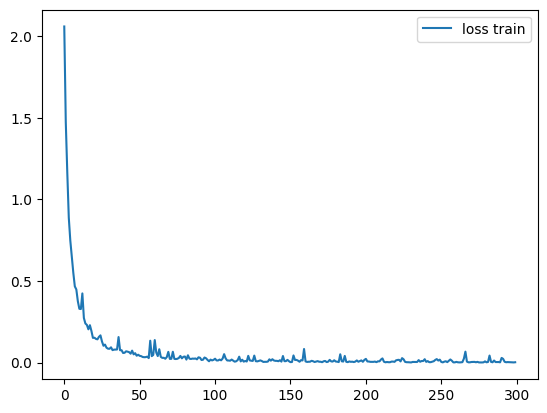

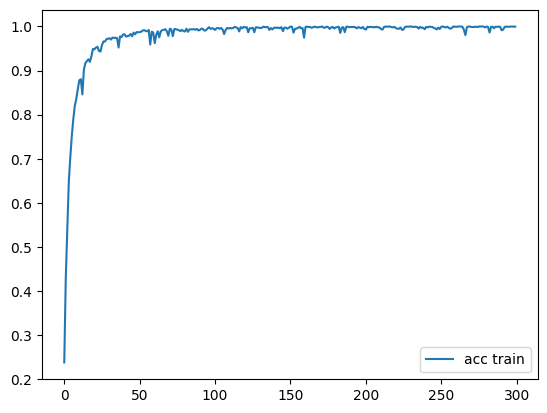

277/277 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

Fold 10 – Treino (MI excluído):
  Alergia: 1.0000
  Autismo: 1.0000
  Bronquite: 1.0000
  Caimbra: 1.0000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Fold 10 – Validação (MI): acc = 0.9200
  Alergia: 1.0000
  Autismo: 0.8000
  Bronquite: 1.0000
  Caimbra: 0.4000
  Convulsao: 1.0000
  Diarreia: 1.0000
  Fratura: 1.0000
  Frieira: 1.0000
  Infarto: 1.0000
  Sarampo: 1.0000

Acurácia Total = 0.8425  |  Desvio = 0.0554
Acurácia Geral = 0.8435


In [8]:
#Listas para juntar as predições de todos os folds
yhat_all = []
ytrue_all = []
fold_results = []

def class_acc(true, pred, labels):
    #Retorna a acurácia de cada classe
    acc = {}
    for i,lbl in enumerate(labels):
        idx = np.where(true == i)[0]
        acc[lbl] = np.mean(pred[idx]==true[idx]) if len(idx)>0 else 0
    return acc

labels = list(label_map.keys())

#Cada fold deixa um sujeito de fora para a validação
for i, val_subj in enumerate(subject_names):
    #Validação: sujeito excluído. Treino: todos os demais
    X_val, y_val = subject_data[val_subj]['X_first'], subject_data[val_subj]['y_first']

    X_train = np.concatenate([subject_data[s]['X_all'] for s in subject_names if s != val_subj])
    y_train = np.concatenate([subject_data[s]['y_all'] for s in subject_names if s != val_subj])

    model = Sequential()
    model.add(InputLayer(input_shape=(num_frames, 225)))
    model.add(Masking(mask_value=0.0))
    model.add(LSTM(neuronios,
        activation='relu',
        return_sequences=False,
        recurrent_dropout=dropout_recorrente))
    model.add(Dense(10, activation='softmax'))
    model.compile(optimizer=AdamW(taxa_aprendizado, weight_decay=weight_decay),
                  loss='categorical_crossentropy',
                  metrics=['categorical_accuracy'])

    hist = model.fit(X_train, y_train,
                     batch_size=batch_size, epochs=epocas, verbose=0)
    model.save(f"{pasta_modelos}/model_fold_{i+1}.keras")

    plt.plot(hist.history['loss'], label='loss train')
    plt.legend()
    plt.show()
    plt.plot(hist.history['categorical_accuracy'], label='acc train')
    plt.legend()
    plt.show()

    #Acurácia por classe no treino
    y_pred_tr = np.argmax(model.predict(X_train), axis=1)
    y_true_tr = np.argmax(y_train, axis=1)
    print(f"\nFold {i+1} – Treino ({val_subj} excluído):")
    for lbl, a in class_acc(y_true_tr, y_pred_tr, labels).items():
        print(f"  {lbl}: {a:.4f}")

    #Acurácia por classe na validação
    y_pred_v = np.argmax(model.predict(X_val), axis=1)
    y_true_v = np.argmax(y_val, axis=1)
    yhat_all.append(y_pred_v)
    ytrue_all.append(y_true_v)

    acc_v = np.mean(y_pred_v == y_true_v)
    fold_results.append(acc_v)
    print(f"Fold {i+1} – Validação ({val_subj}): acc = {acc_v:.4f}")
    for lbl, a in class_acc(y_true_v, y_pred_v, labels).items():
        print(f"  {lbl}: {a:.4f}")

#Média e desvio padrão da acurácia entre os folds
media = np.mean(fold_results)
std = np.std(fold_results)
print(f"\nAcurácia Total = {media:.4f}  |  Desvio = {std:.4f}")

#Acurácia geral, juntando as predições de todos os folds
y_true_final = np.concatenate(ytrue_all)
y_pred_final = np.concatenate(yhat_all)
acc_final = np.mean(y_pred_final == y_true_final)
print(f"Acurácia Geral = {acc_final:.4f}")